# PathSnap · Team 111 — Bayesian hyperparameter optimisation
**Deliverable: Bayesian optimisation code, search configurations and experiment results.**

Model tuned: **HistGradientBoosting**, selected in `03_model_training_evaluation.ipynb`.
Input: `data/processed/fe/` from notebook 02. Run order: 01 → 02 → (03) → 04.

| Step | What |
|---|---|
| 1 | Search space (search configuration) |
| 2 | Objective function (group-aware CV) |
| 3 | Our Bayesian optimiser: Gaussian-process surrogate + Expected Improvement, written out in full |
| 4 | Run the optimisation (trial log) |
| 5 | Convergence and parameter plots |
| 6 | Tuned vs untuned, same protocol |
| 7 | Save the tuned model and its probabilities (used by the HMM in notebook 05) |

## Step 0 — Setup

In [1]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, log_loss
warnings.filterwarnings("ignore")

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
if os.path.isdir("/content"):
    ROOT = "/content"
FE = os.path.join(ROOT, "data", "processed", "fe")
RES = os.path.join(ROOT, "results"); os.makedirs(RES, exist_ok=True)
MOD = os.path.join(ROOT, "models", "notebook"); os.makedirs(MOD, exist_ok=True)
assert os.path.exists(os.path.join(FE, "train_features.pkl")), "Run 02_feature_engineering.ipynb first"
SEED = 111
FEATURES = pd.read_csv(os.path.join(RES, "fe_feature_list.csv")).feature.tolist()
tr = pd.read_pickle(os.path.join(FE, "train_features.pkl"))
te = pd.read_pickle(os.path.join(FE, "student_test_features.pkl"))
print(f"train {len(tr):,} rows ({tr.trip.nunique()} trips) | student_test {len(te):,} rows")

train 341,192 rows (78 trips) | student_test 113,694 rows


## Step 1 — Search space
Six HistGB hyperparameters. Learning rate, tree size, leaf size and L2 strength act multiplicatively, so they are
searched on a **log scale**. The optimiser works in the unit cube [0, 1]^6; `decode()` maps a point to real values.

In [2]:
SPACE = [  # name, low, high, log-scale, integer
    ("learning_rate",     0.01, 0.3,  True,  False),
    ("max_leaf_nodes",    8,    128,  True,  True),
    ("min_samples_leaf",  10,   400,  True,  True),
    ("l2_regularization", 1e-4, 10.0, True,  False),
    ("max_iter",          100,  600,  False, True),
    ("max_features",      0.4,  1.0,  False, False),
]
UNTUNED = dict(learning_rate=0.1, max_iter=200, max_leaf_nodes=31)   # the configuration used in notebook 03


def decode(u):
    out = {}
    for x, (name, lo, hi, log, integer) in zip(u, SPACE):
        v = np.exp(np.log(lo) + x * (np.log(hi) - np.log(lo))) if log else lo + x * (hi - lo)
        out[name] = int(round(v)) if integer else float(v)
    return out


pd.DataFrame(SPACE, columns=["hyperparameter", "low", "high", "log_scale", "integer"])

,hyperparameter,low,high,log_scale,integer
0,learning_rate,0.0100,0.3,True,False
1,max_leaf_nodes,8.0000,128.0,True,True
2,min_samples_leaf,10.0000,400.0,True,True
3,l2_regularization,0.0001,10.0,True,False
4,max_iter,100.0000,600.0,False,True
5,max_features,0.4000,1.0,False,False


## Step 2 — Objective function
**Mean macro F1 over 3-fold GroupKFold** (groups = trips) on the training trips. To keep each trial fast,
the optimisation uses every 3rd row of the (already 1-in-3) training table — so 1 in 9 GPS points.
The final comparison in Step 6 uses the full table and the 5 folds from notebook 02.

In [3]:
bo = tr[tr.pt % 9 == 0].reset_index(drop=True)
Xb, yb, gb = bo[FEATURES].values, bo.y.values, bo.trip.values
bo_folds = list(GroupKFold(n_splits=3).split(Xb, yb, gb))
print(f"optimisation data: {len(bo):,} rows, {bo.trip.nunique()} trips, 3 group folds")


def objective(params):
    scores = []
    for a, b in bo_folds:
        m = HistGradientBoostingClassifier(random_state=SEED, **params).fit(Xb[a], yb[a])
        scores.append(f1_score(yb[b], (m.predict_proba(Xb[b])[:, 1] >= .5).astype(int), average="macro"))
    return float(np.mean(scores)), float(np.std(scores))

optimisation data: 113,901 rows, 78 trips, 3 group folds


## Step 3 — The Bayesian optimiser
1. **Surrogate:** a Gaussian process (Matérn-5/2 kernel + white noise) fitted to all (configuration → score)
   pairs seen so far. It predicts a mean **μ(x)** and an uncertainty **σ(x)** for any untried configuration.
2. **Acquisition — Expected Improvement:** with best score so far f*,
   `EI(x) = (μ − f* − ξ)·Φ(z) + σ·φ(z)`,  `z = (μ − f* − ξ)/σ`.
   High where the GP predicts a good score (exploitation) **or** is very uncertain (exploration).
3. **Next trial** = the configuration with the highest EI among 4,000 random candidates.
4. The first 6 trials are random to give the GP something to learn from.

In [4]:
def expected_improvement(mu, sd, best, xi=1e-4):
    sd = np.maximum(sd, 1e-9)
    z = (mu - best - xi) / sd
    return (mu - best - xi) * norm.cdf(z) + sd * norm.pdf(z)


def propose(U, Y, rng, n_candidates=4000):
    kernel = ConstantKernel(1.0) * Matern(length_scale=np.ones(len(SPACE)), nu=2.5) + WhiteKernel(1e-4)
    gp = GaussianProcessRegressor(kernel, normalize_y=True, n_restarts_optimizer=3, random_state=SEED)
    gp.fit(np.array(U), np.array(Y))
    cand = rng.rand(n_candidates, len(SPACE))
    mu, sd = gp.predict(cand, return_std=True)
    ei = expected_improvement(mu, sd, max(Y))
    i = int(np.argmax(ei))
    return cand[i], float(mu[i]), float(sd[i]), float(ei[i])

## Step 4 — Run the optimisation (6 random + 14 GP-EI = 20 trials)

In [5]:
N_INIT, N_ITER = 6, 14
rng = np.random.RandomState(SEED)
U, Y, trials = [], [], []
t_all = time.time()
for it in range(N_INIT + N_ITER):
    if it < N_INIT:
        u, mu, sd, ei, how = rng.rand(len(SPACE)), np.nan, np.nan, np.nan, "random"
    else:
        (u, mu, sd, ei), how = propose(U, Y, rng), "GP-EI"
    params = decode(u)
    t0 = time.time(); f1, f1_sd = objective(params)
    U.append(u); Y.append(f1)
    trials.append(dict(trial=it, strategy=how, cv_macro_f1=f1, cv_std=f1_sd, gp_predicted=mu, gp_uncertainty=sd,
                       expected_improvement=ei, best_so_far=max(Y), seconds=time.time() - t0, **params))
    print(f"trial {it:2d} {how:6s} F1={f1:.4f} best={max(Y):.4f}  "
          + ", ".join(f"{k}={v:.4g}" for k, v in params.items()))
bo_seconds = time.time() - t_all
trials = pd.DataFrame(trials)
trials.to_csv(os.path.join(RES, "nb_bayes_opt_trials.csv"), index=False)
best = trials.loc[trials.cv_macro_f1.idxmax()]
BEST = {name: (int(best[name]) if integer else float(best[name])) for name, _, _, _, integer in SPACE}
print(f"\n{len(trials)} trials in {bo_seconds:.0f} s; best trial {int(best.trial)} ({best.strategy}): F1 {best.cv_macro_f1:.4f}")
BEST

trial  0 random F1=0.9378 best=0.9378  learning_rate=0.08021, max_leaf_nodes=13, min_samples_leaf=50, l2_regularization=0.702, max_iter=248, max_features=0.4895
trial  1 random F1=0.9385 best=0.9385  learning_rate=0.01079, max_leaf_nodes=26, min_samples_leaf=24, l2_regularization=0.004878, max_iter=595, max_features=0.5426
trial  2 random F1=0.9385 best=0.9385  learning_rate=0.01318, max_leaf_nodes=51, min_samples_leaf=99, l2_regularization=0.002351, max_iter=333, max_features=0.471
trial  3 random F1=0.9391 best=0.9391  learning_rate=0.01286, max_leaf_nodes=97, min_samples_leaf=187, l2_regularization=1.595, max_iter=508, max_features=0.9946
trial  4 random F1=0.9378 best=0.9391  learning_rate=0.07124, max_leaf_nodes=76, min_samples_leaf=47, l2_regularization=0.0001372, max_iter=327, max_features=0.4632
trial  5 random F1=0.9373 best=0.9391  learning_rate=0.1611, max_leaf_nodes=55, min_samples_leaf=80, l2_regularization=0.00235, max_iter=599, max_features=0.4828
trial  6 GP-EI  F1=0.92

{'learning_rate': 0.012860098349830868, 'max_leaf_nodes': 97, 'min_samples_leaf': 187, 'l2_regularization': 1.5953215934534963, 'max_iter': 508, 'max_features': 0.9945729107982461}

## Step 5 — Convergence and how each hyperparameter relates to the score

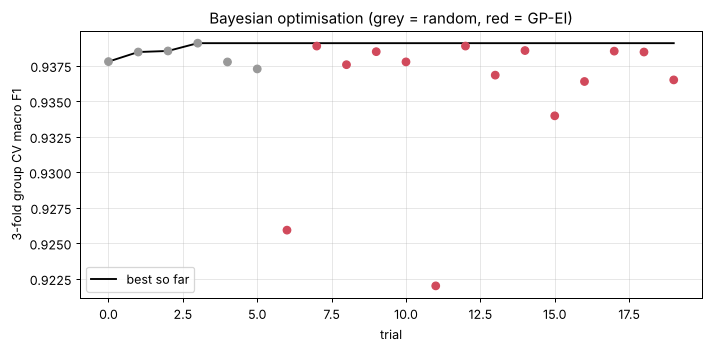

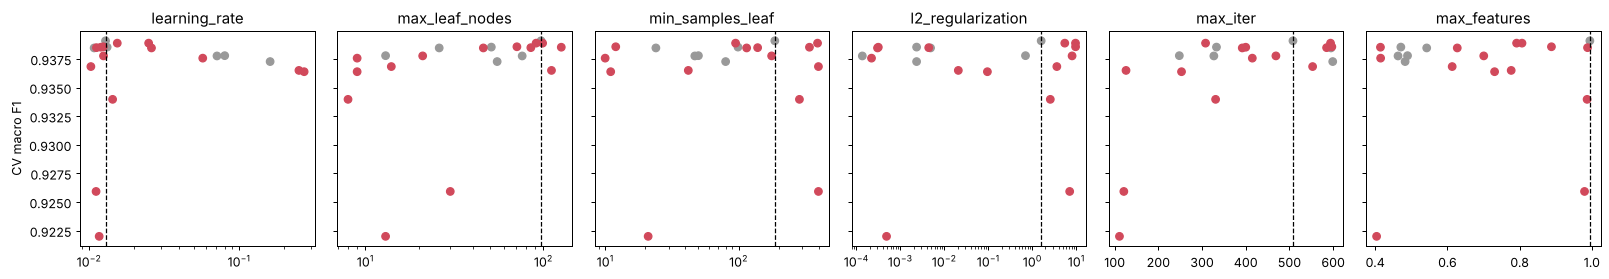

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(trials.trial, trials.cv_macro_f1, c=np.where(trials.strategy == "GP-EI", "#d1495b", "#999999"), zorder=3)
ax.plot(trials.trial, trials.best_so_far, color="k", label="best so far")
ax.set(xlabel="trial", ylabel="3-fold group CV macro F1", title="Bayesian optimisation (grey = random, red = GP-EI)")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 6, figsize=(18, 3.2), sharey=True)
for a, (name, lo, hi, log, _) in zip(axs, SPACE):
    a.scatter(trials[name], trials.cv_macro_f1, c=np.where(trials.strategy == "GP-EI", "#d1495b", "#999999"))
    a.axvline(BEST[name], color="k", ls="--", lw=1)
    if log:
        a.set_xscale("log")
    a.set(title=name)
axs[0].set_ylabel("CV macro F1"); plt.tight_layout(); plt.show()

## Step 6 — Tuned vs untuned (identical protocol)
Both configurations: 5-fold group CV on the full training table (folds from notebook 02), refit on all
training rows, evaluate on student_test.

In [7]:
def top1(df, p):
    d = df[["trip", "pt", "y"]].copy(); d["p"] = p
    return float(d.loc[d.groupby(["trip", "pt"]).p.idxmax()].y.mean())


Xtr, ytr, folds = tr[FEATURES].values, tr.y.values, tr.fold.values
Xte, yte = te[FEATURES].values, te.y.values
rows, models, test_probs = [], {}, {}
for name, params in [("HistGB untuned", UNTUNED), ("HistGB tuned", BEST)]:
    oof = np.zeros(len(tr)); f1s = []
    for k in range(5):
        a, b = folds != k, folds == k
        m = HistGradientBoostingClassifier(random_state=SEED, **params).fit(Xtr[a], ytr[a])
        oof[b] = m.predict_proba(Xtr[b])[:, 1]
        f1s.append(f1_score(ytr[b], (oof[b] >= .5).astype(int), average="macro"))
    t0 = time.time(); m = HistGradientBoostingClassifier(random_state=SEED, **params).fit(Xtr, ytr); fit_s = time.time() - t0
    t0 = time.time(); p = m.predict_proba(Xte)[:, 1]; inf_s = time.time() - t0
    models[name], test_probs[name] = m, p
    rows.append(dict(model=name, cv_macro_f1=np.mean(f1s), cv_macro_f1_std=np.std(f1s), cv_top1=top1(tr, oof),
                     test_top1=top1(te, p), test_macro_f1=f1_score(yte, (p >= .5).astype(int), average="macro"),
                     test_log_loss=log_loss(yte, np.clip(p, 1e-6, 1 - 1e-6)), train_time_s=fit_s, inference_s=inf_s))
cmp_ = pd.DataFrame(rows)
cmp_.to_csv(os.path.join(RES, "nb_tuned_vs_untuned.csv"), index=False)
cmp_.round(4)

,model,cv_macro_f1,cv_macro_f1_std,cv_top1,test_top1,test_macro_f1,test_log_loss,train_time_s,inference_s
0,HistGB untuned,0.9386,0.0144,0.9042,0.8847,0.9298,0.0974,1.8813,0.1224
1,HistGB tuned,0.9398,0.0139,0.9071,0.8964,0.9379,0.0891,18.3371,1.0844


change from tuning: CV macro F1 +0.0012, test Top-1 +0.0117, test log loss -0.0084


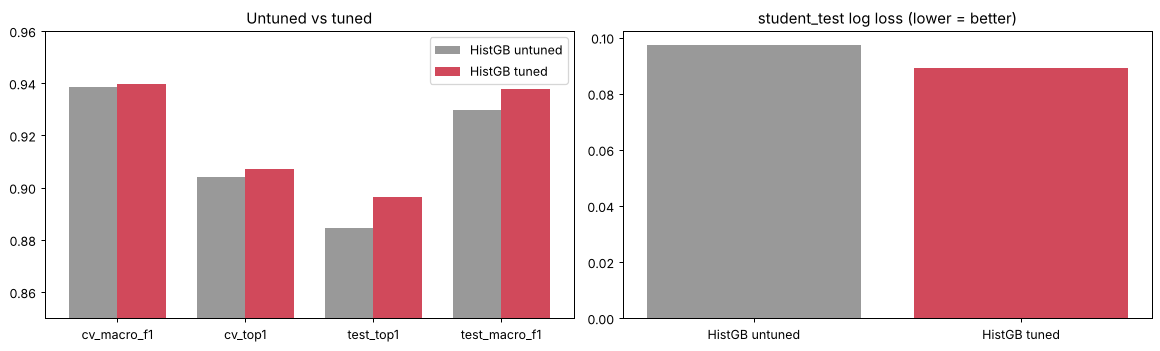

In [8]:
cols = ["cv_macro_f1", "cv_top1", "test_top1", "test_macro_f1"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); xx = np.arange(len(cols))
for k, (_, r) in enumerate(cmp_.iterrows()):
    ax[0].bar(xx + (k - .5) * .38, r[cols].astype(float), .38, label=r.model, color=["#999999", "#d1495b"][k])
ax[0].set(xticks=xx, xticklabels=cols, ylim=(0.85, 0.96), title="Untuned vs tuned"); ax[0].legend()
ax[1].bar(cmp_.model, cmp_.test_log_loss, color=["#999999", "#d1495b"]); ax[1].set(title="student_test log loss (lower = better)")
plt.tight_layout(); plt.show()
d = cmp_.set_index("model")
print(f"change from tuning: CV macro F1 {d.cv_macro_f1.iloc[1] - d.cv_macro_f1.iloc[0]:+.4f}, "
      f"test Top-1 {d.test_top1.iloc[1] - d.test_top1.iloc[0]:+.4f}, "
      f"test log loss {d.test_log_loss.iloc[1] - d.test_log_loss.iloc[0]:+.4f}")

## Step 7 — Save
The tuned model and its search record are saved; notebook 05 uses the tuned configuration for the HMM emissions.

In [9]:
joblib.dump(models["HistGB tuned"], os.path.join(MOD, "histgb_tuned.joblib"))
json.dump(dict(best_params=BEST, best_cv3_macro_f1=float(best.cv_macro_f1), n_trials=len(trials),
               n_random=N_INIT, n_gp_ei=N_ITER, total_seconds=bo_seconds, objective="mean macro F1, 3-fold GroupKFold, 1/9 of observations",
               search_space=[dict(name=n, low=lo, high=hi, log=lg, integer=it) for n, lo, hi, lg, it in SPACE]),
          open(os.path.join(RES, "nb_bayes_opt_best.json"), "w"), indent=2)
print("saved: models/notebook/histgb_tuned.joblib, results/nb_bayes_opt_trials.csv, nb_bayes_opt_best.json, nb_tuned_vs_untuned.csv")

saved: models/notebook/histgb_tuned.joblib, results/nb_bayes_opt_trials.csv, nb_bayes_opt_best.json, nb_tuned_vs_untuned.csv


## Summary
- **Search configuration:** 6 hyperparameters, log scales where multiplicative, 20 trials (6 random + 14 GP-EI).
- **Optimiser:** our own Gaussian-process + Expected-Improvement loop (scikit-learn GP), fully shown above.
- **Result:** the best configuration came from one of the 6 random initial trials (trial 3, CV F1 0.9391); the
  GP-EI trials concentrated around it (0.9385–0.9389) without beating it — the score surface is flat near the
  optimum. Against the untuned model (same protocol) the tuned one gains +0.0012 CV macro F1 (well within the
  fold-to-fold spread), **+1.2 points student_test Top-1** and lowers log loss 0.0974 → 0.0891 — better-calibrated
  probabilities, which matters for the HMM in notebook 05. Cost: ~10× slower training and inference.